In [1]:
import os
from skimage import io
import pandas as pd
import pickle
from pathlib import Path
import PF_functions as PF
import pandas as pd
from oiffile import imread, OifFile # probably won't be used but from Gabe's version
from tifffile import imread, TiffFile
import matplotlib
# matplotlib.use('TkAgg')
import matplotlib.pyplot as plt
import numpy as np
from numpy import argmax, argmin

## Optimizing parameters for PunctaFinder

**Step 1:** Creating validated dataset 
(uses mask obtained with manually traced cell outlines in ImageJ, at least for now)

In [ ]:
## preprocess cell mask images for generating validated dataset

mask_img = io.imread("D:\\anatomy_data\\DK95\\MaskID-DK95_slide2_section5_40x_CTB.tif")
puncta_img = io.imread("D:\\anatomy_data\\DK95\\C2-DK95_slide2_section5_40x_EGFP.tif")

# convert image into array with same dimensions as the mask image
mask = np.array(mask_img) # [z, y, x] dimensions

In [ ]:
## Define functions for preprocessing masks with cell outlines obtained from imageJ: connect open lines and fill blobs
# may not be used depending on macro functioning in imageJ

import numpy as np
import tifffile as tiff
from scipy.ndimage import binary_fill_holes
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize
from skimage.draw import line


def find_endpoints(binary_mask):
    """Finds the endpoints of a 1-pixel wide skeletonized curve."""
    # Ensure the line is strictly 1 pixel wide to accurately locate endpoints
    skeleton = skeletonize(binary_mask)
    
    # A pixel is an endpoint if it has exactly 1 neighbor in a 3x3 neighborhood
    # We use a custom kernel convolution equivalent to count neighbors
    from scipy.ndimage import convolve
    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]], dtype=np.uint8)
    
    neighbor_count = convolve(skeleton.astype(np.uint8), kernel, mode='constant')
    
    # Endpoints are skeleton pixels that have exactly 1 neighbor
    endpoint_mask = skeleton & (neighbor_count == 1)
    
    # Return coordinates as an array of (Y, X) pairs
    return np.argwhere(endpoint_mask)


def fill_blob_outlines(input_path, output_path):
    print(f"Reading multi-page TIFF: {input_path}")
    # Read the 3D stack (Z, Y, X)
    stack = tiff.imread(input_path)
    
    # Handle single-slice edge case if the tiff is read as 2D
    if stack.ndim == 2:
        stack = np.expand_dims(stack, axis=0)
        
    filled_stack = np.zeros_like(stack)
    num_slices = stack.shape[0]
    
    for z in range(num_slices):
        slice_data = stack[z]
        unique_labels = np.unique(slice_data)
        unique_labels = unique_labels[unique_labels != 0]
        
        filled_slice = np.zeros_like(slice_data)
        
        for label in unique_labels:
            outline_mask = (slice_data == label)
            
            # --- Auto-Closing Logic ---
            # Attempt to fill holes first. If it's an open line, 
            # binary_fill_holes will change nothing or fail to enclose an area.
            filled_mask = binary_fill_holes(outline_mask)
            
            # If the filled mask is identical to the outline, it means no interior 
            # holes were found (likely an open line or a solid block)
            if np.array_equal(filled_mask, outline_mask):
                endpoints = find_endpoints(outline_mask)
                
                # If we exactly find 2 endpoints, we bridge them with a straight line
                if len(endpoints) == 2:
                    y0, x0 = endpoints[0]
                    y1, x1 = endpoints[1]
                    
                    # Generate pixel coordinates linking the two ends
                    rr, cc = line(y0, x0, y1, x1)
                    
                    # Create a copy of the mask and stitch the gap closed
                    closed_outline = outline_mask.copy()
                    closed_outline[rr, cc] = True
                    
                    # Try filling again now that the loop is complete
                    filled_mask = binary_fill_holes(closed_outline)
            # ---------------------------
            
            filled_slice[filled_mask] = label
            
        filled_stack[z] = filled_slice
        print(f" -> Processed slice {z+1}/{num_slices} (Found {len(unique_labels)} blobs)")

        # Optional: visualize the first slice of the filled stack
        # plt.imshow(filled_stack[z], cmap='viridis')
        # plt.title('Filled Mask')
        # plt.show()

    print(f"Saving filled stack to: {output_path}")
    tiff.imwrite(output_path, filled_stack, compression='zlib')
    print("Processing complete!")
    


In [ ]:
input_path = "D:\\anatomy_data\\DK95\\MaskID-DK95_slide2_section5_40x_CTB.tif"
output_path = "D:\\anatomy_data\\DK95\\FilledMask-DK95_slide2_section5_40x_CTB.tif"

fill_blob_outlines(input_path, output_path)


In [227]:
# read image file with GFP puncta
puncta_img = tiff.imread("D:\\anatomy_data\\DK95\\C2-DK95_slide2_section5_40x_EGFP.tif")
validation_EFGP = tiff.imread("D:\\anatomy_data\\DK95\\C2-DK95_slide2_section5_40x_EGFP.tif")[3]
mask_path = "D:\\anatomy_data\\DK95\\MaskID-DK95_slide2_section5_40x_FB.tif"


In [ ]:

# read output file, then generate a mask of a slice with a single cell, then visualize the mask
filled_stack = tiff.imread(output_path)
validation_mask = filled_stack[3] == 18

# delete all empty rows from validation_mask
row_indices = np.any(validation_mask, axis=1)
validation_mask = validation_mask[row_indices]
# do the same for columns
col_indices = np.any(validation_mask, axis=0)
validation_mask = validation_mask[:, col_indices]
# add padding of 20 pixels around the mask
validation_mask = np.pad(validation_mask, pad_width=20, mode='constant', constant_values=0)

# # visualize validation_mask
# plt.imshow(validation_mask)
# plt.show()

# crop validation_EGFP to match the validation_mask
EGFP_cropped = validation_EFGP[row_indices][:, col_indices]
# pad EGFP_cropped with 20 pixels of zeros around the edges to match the validation_mask
EGFP_cropped = np.pad(EGFP_cropped, pad_width=20, mode='constant', constant_values=0)

# plot masked cell using PF function
PF.plot_masked_cell(EGFP_cropped,validation_mask)

# if above PF function doesn't work:
# # overlap puncta_img and validation_mask, then visualize
# overlapped_img = np.where(validation_mask, EGFP_cropped, 0)

# # visualize overlapped_img
# plt.imshow(overlapped_img)
# plt.show()

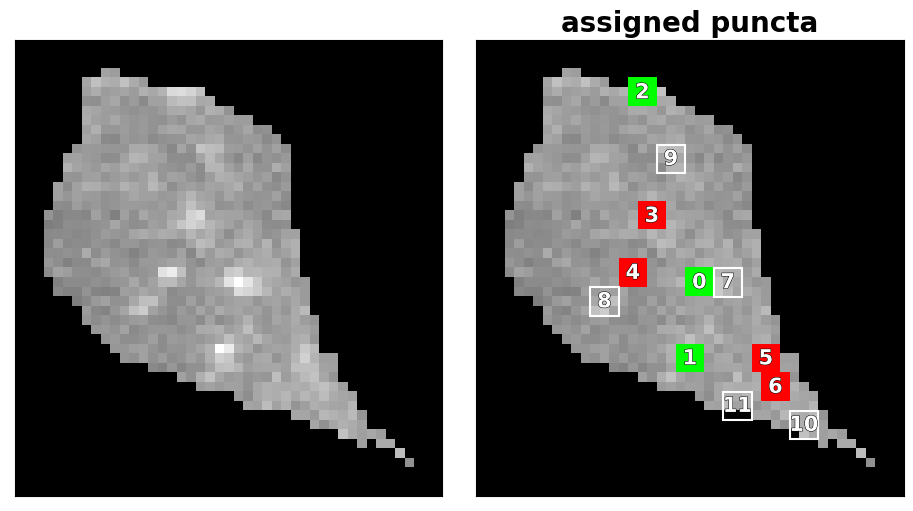

In [8]:
diameter = 3
overlap = 0
df_validated = pd.DataFrame({})

N_cat1 = 3
N_cat2 = 4
N_cat3 = 0

# run PF for dataset creation
df_cell, cropped_cell, mask_cat1, mask_cat2, mask_cat3 = PF.PF_validated_data(EGFP_cropped, validation_mask, diameter, overlap, N_cat1, N_cat2, N_cat3)
PF.plot_PF_validated_data(df_cell, cropped_cell, mask_cat1, mask_cat2, mask_cat3)



In [ ]:
# make manual changes to df as needed
df_cell.at[4, "state"] = "category 1"
df_cell.at[2, "state"] = "category 2"
df_cell.at[6, "state"] = "nonpunctate"
df_cell.at[8, "state"] = "category 2"

# add validated data pertaining to one cell (`df_cell`) to the dataframe with all data (`df_validated`)
df_validated = pd.concat([df_validated, df_cell])


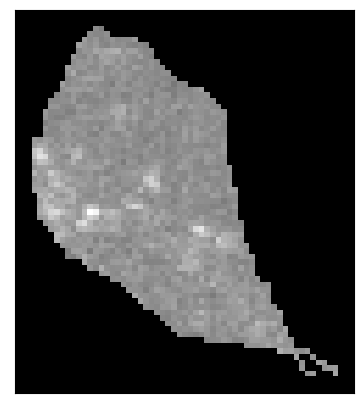

In [294]:
# loop over all slices in filled_stack to plot masked cells one at a time for each slice
for i in range(filled_stack.shape[0]-5):
    # get the mask for the current slice
    current_mask = filled_stack[i] > 0  # assuming non-zero values indicate cells
    cells_in_slice = np.unique(filled_stack[i][current_mask])

    if len(cells_in_slice) == 0:
        continue  # skip slices with no cells

    elif len(cells_in_slice) > 1:
        # print(f"Slice {i} has multiple cells: {cells_in_slice}.")
        # For now, we will just take the first cell for demonstration purposes
        selected_cell = cells_in_slice[1]
        current_mask = filled_stack[i] == selected_cell
    
        # crop the corresponding EGFP slice to match the current mask
        current_EGFP = puncta_img[i]
        
        # delete all empty rows from current_mask
        row_indices = np.any(current_mask, axis=1)
        current_mask_cropped = current_mask[row_indices]
        current_EGFP_cropped = current_EGFP[row_indices]
        
        # do the same for columns
        col_indices = np.any(current_mask_cropped, axis=0)
        current_mask_cropped = current_mask_cropped[:, col_indices]
        current_EGFP_cropped = current_EGFP_cropped[:, col_indices]
        
        # add padding of 20 pixels around the mask
        current_mask_padded = np.pad(current_mask_cropped, pad_width=20, mode='constant', constant_values=0)
        current_EGFP_padded = np.pad(current_EGFP_cropped, pad_width=20, mode='constant', constant_values=0)
        
        # plot masked cell using PF function
        PF.plot_masked_cell(current_EGFP_padded, current_mask_padded)

    # # pause until user closes the plot before continuing to the next slice
    # user_input = input("Press Enter to continue to the next slice, or type 'exit' to stop: ")
    # if user_input.lower() == 'exit':
    #     break




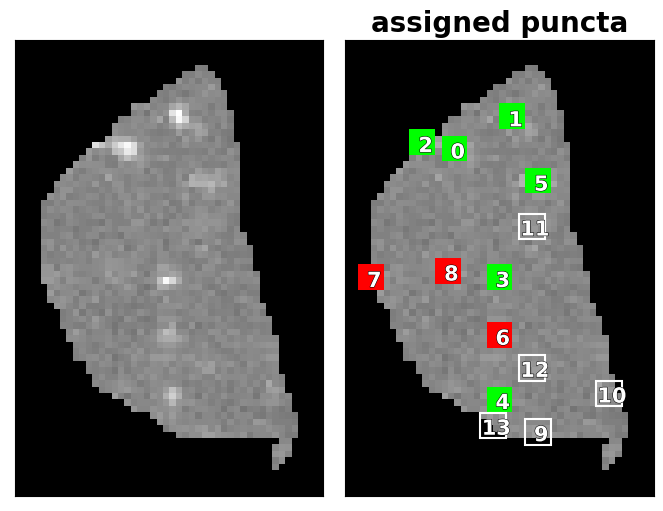

In [ ]:
diameter = 4
overlap = 0

N_cat1 = 
N_cat2 = 3
N_cat3 = 0

# run PF for dataset creation
df, cropped_cell, mask_cat1, mask_cat2, mask_cat3 = PF.PF_validated_data(current_EGFP_padded, current_mask_padded, diameter, overlap, N_cat1, N_cat2, N_cat3)
PF.plot_PF_validated_data(df, cropped_cell, mask_cat1, mask_cat2, mask_cat3)


In [ ]:
df_cell_10

In [290]:
# make manual changes to df as needed
df.at[7, "state"] = "nonpunctate"
# df.at[13, "state"] = "nonpunctate"
df.at[5, "state"] = "category 2"
# df.at[8, "state"] = "category 2"
# df.at[15, "state"] = "category 1"
# df.at[6, "state"] = "nonpunctate"
# df.at[8, "state"] = "category 2"


In [291]:
# df_validated = pd.DataFrame({})
# add validated data pertaining to one cell (`df_cell`) to the dataframe with all data (`df_validated`)
df_validated_FB = pd.concat([df_validated_FB, df])

In [365]:

# set column 1 header to "cellID"
df_validated_FB.columns.values[0] = "cellID"

df_validated_FB
# # save the dataframe (once it is complete)
# df_validated_FB.to_csv("./validated_dataset_DK95_slide2_section5_40x_FB.csv")

,cellID,x,y,diameter,"intensity ratio, local","intensity ratio, overall",CV,state
0,0,15,35,4,1.435982,1.597802,0.206950,category 1
1,1,21,9,4,1.248749,1.213198,0.176110,category 1
2,2,17,15,4,1.235807,1.211947,0.126025,category 1
3,3,14,7,4,1.188743,1.196099,0.142212,category 1
4,4,19,34,4,1.096952,1.190886,0.138153,category 1
...,...,...,...,...,...,...,...,...
127,26,15,22,4,1.014123,1.011464,0.061740,nonpunctate
128,27,9,47,4,1.052041,1.010922,0.049923,nonpunctate
129,28,30,34,4,1.038202,1.007171,0.082576,nonpunctate
130,29,19,27,4,1.028174,1.003329,0.057714,nonpunctate


**Step 2:** Determine optimal threshold values

In [358]:
df_validated_FB = pd.read_csv("./validated_dataset_DK95_slide2_section5_40x_FB.csv", header = 0, sep = ',')

# set the weighting factor for false negatives
FN_weight = 0.75  # within the test statistic according to `test_statistic = #FPs + FN_weight * #FNs`

# set threshold values to test. For each of 3 punctum selection criteria, user sets min, max, and step size values.
# The values are stored in a list, and 3 such lists (one per punctum selection criterion) are the inputs of the function `potential thresholds`.

# for each criterion create a list with [min_threshold, max_threshold, stepsize]
T_local_vals = [1, 2, 0.05]
T_global_vals = [1, 3, 0.05]
T_cv_vals = [0.1, 0.8, 0.05]

# create a suitable input for the threshold optimisation function
potential_thresholds = PF.potential_threshold_values(T_local_vals, T_global_vals, T_cv_vals)

# define what should/should not be detected
should_detect = ['category 1']
should_not_detect = ['category 2','nonpunctate']

In [301]:
# perform threshold optimization
T_local, T_global, T_CV = PF.thresholds_all_data(df_validated_FB, FN_weight, potential_thresholds, should_detect, should_not_detect)

OPTIMAL COMBINATION OF THRESHOLD VALUES:
local intensity ratio: 1.05
global intensity ratio: 1.1500000000000001
CV: 0.30000000000000004

 0 FPs; 7 FNs


In [ ]:
# run threshold optimization function with different threshold values to test the robustness of the optimization process. This can be done by generating random threshold values within a specified range and running the optimization multiple times.

n_iterations = 50
thresholds = []

for i in range(n_iterations):
    print(f"Iteration {i+1}/{n_iterations}")
    
    FN_weight = 0.8  # within the test statistic according to `test_statistic = #FPs + FN_weight * #FNs`
    should_detect = ['category 1', 'category 2']
    should_not_detect = ['nonpunctate']
    
    # generate random threshold values for T_local, T_global, and T_cv
    T_local_vals = [np.random.uniform(1.0, 2.0), np.random.uniform(2.0, 3.0), 0.05]
    T_global_vals = [np.random.uniform(1.0, 2.0), np.random.uniform(2.0, 3.0), 0.05]
    T_cv_vals = [np.random.uniform(0.1, 0.5), np.random.uniform(0.5, 0.9), 0.05]

    # create a suitable input for the threshold optimisation function
    potential_thresholds = PF.potential_threshold_values(T_local_vals, T_global_vals, T_cv_vals)

    # perform threshold optimization
    T_local, T_global, T_CV = PF.thresholds_all_data(df_validated, FN_weight, potential_thresholds, should_detect, should_not_detect)

    # store threshold values for each iteration   
    thresholds.append((T_local, T_global, T_CV))

# # print index of iteration with minimum false negatives
# min_FN_index = np.argmin([fn for fp, fn in falses])

# print("Index of iteration with minimum false negatives:", min_FN_index)


In [27]:
# print(len(thresholds))

# local intensity ratio: 1.003814299513937
# global intensity ratio: 1.140489113712209
# CV: 0.32795242384623446
#  9 FPs; 12 FNs

T_local = 1.003814299513937
T_global = 1.140489113712209
T_CV = 0.32795242384623446


## from demo **with** bootstrapping
step 5: add a unique identifier for this cell to the dataframe.

This identifier is an integer number; the column will be named cellID.

This information will be used for bootstrapping in the threshold value optimisation (splitting the total dataset into a training set and a test set).

In [2]:
df_validated_CTB = pd.read_csv("./validated_dataset_DK95_slide2_section5_40x_CTB.csv", header = 0, sep = ',')

In [5]:
# 1. Check if the DataFrame is empty OR if the column doesn't exist yet
if len(df_validated_CTB) == 0 or "cellID" not in df_validated_CTB.columns:
    identifier = 1
else:
    # 2. Optimized way to find the max value using pandas native .max()
    identifier = df_validated_CTB["cellID"].max() + 1
    
# 3. Assign the new identifier to your other DataFrame
df_validated_CTB["cellID"] = identifier
print()

In [ ]:
df_validated_CTB.columns.values[0] = "cellID"


In [ ]:
df_validated_CTB

,cellID,x,y,diameter,"intensity ratio, local","intensity ratio, overall",CV,state
0,0,23,25,3,1.338459,1.386555,0.167002,category 1
1,1,22,33,3,1.269120,1.301037,0.194546,category 1
2,2,17,5,3,1.277075,1.298279,0.089257,category 2
3,3,18,18,3,1.216647,1.230348,0.105145,category 2
4,4,16,24,3,1.236884,1.186899,0.177162,category 1
...,...,...,...,...,...,...,...,...
531,50,20,4,3,1.001339,1.005700,0.037938,nonpunctate
532,51,21,7,3,1.006760,1.005354,0.055343,nonpunctate
533,52,12,4,3,1.017524,1.003276,0.070659,nonpunctate
534,53,29,24,3,1.009657,1.002584,0.071106,nonpunctate


Section 2: Threshold value optimisation (with bootstrapping)
Approach:

- Split data set 66%/33% into training and test set. 
- Determine the optimal combination of threshold values based on the training set and apply the obtained thresholds to the test set;
- Bootstrapping: repeat the whole approach for a user-defined number of iterations;
- Visualise the obtained threshold values, difference in # puncta detected between manual detection and with PunctaFinder, and FP and FN occurrence rates for both training and test set for each bootstrap iteration;
- For each of the three punctum detection criteria, determine the mean value across the bootstrap iterations so that this value can be used in all further data analysis.

In [28]:

iterations = 10
# test_statistic = FPs + FNs * FN_weight (weighting factor for importance of FN prevention over FP prevention)
# weight < 0: prevention of false positives is valued more than prevention of false negatives
FN_weight = 0.75
# for each criterion create a list with [min_threshold, max_threshold, stepsize]
# T_local_vals = [1.5, 3, 0.1]
# T_global_vals = [2.5, 8, 0.1]
# T_cv_vals = [0.1, 0.5, 0.05]
# T_local_vals = [0.5, 4, 0.05]
# T_global_vals = [0.5, 5, 0.05]
# T_cv_vals = [0.05, 1, 0.05]
T_local_vals = [1, 2, 0.05]
T_global_vals = [1, 3, 0.05]
T_cv_vals = [0.1, 0.8, 0.05]
potential_thresholds = PF.potential_threshold_values(T_local_vals, T_global_vals, T_cv_vals)

should_detect = ['category 1']
should_not_detect = ['category 3', 'nonpunctate']


In [29]:

av_thresholds, N_total, N_training_test, thresholds, differences, errors = PF.thresholds_bootstrap(df_validated_CTB, iterations, FN_weight, potential_thresholds, should_detect, should_not_detect) 

iteration 1 finished; obtained threshold values: ratio_local: 1.1 ; ratio_global: 1.2000000000000002 ; CV: 0.25000000000000006
iteration 2 finished; obtained threshold values: ratio_local: 1.05 ; ratio_global: 1.2000000000000002 ; CV: 0.25000000000000006
iteration 3 finished; obtained threshold values: ratio_local: 1.1 ; ratio_global: 1.1500000000000001 ; CV: 0.25000000000000006
iteration 4 finished; obtained threshold values: ratio_local: 1.1 ; ratio_global: 1.1500000000000001 ; CV: 0.25000000000000006
iteration 5 finished; obtained threshold values: ratio_local: 1.05 ; ratio_global: 1.1500000000000001 ; CV: 0.3500000000000001
iteration 6 finished; obtained threshold values: ratio_local: 1.05 ; ratio_global: 1.2000000000000002 ; CV: 0.3500000000000001
iteration 7 finished; obtained threshold values: ratio_local: 1.1 ; ratio_global: 1.2000000000000002 ; CV: 0.25000000000000006
iteration 8 finished; obtained threshold values: ratio_local: 1.05 ; ratio_global: 1.2000000000000002 ; CV: 0.

Section 3: Visualising the outcomes
of all bootstrap iterations

The visualisations are:

- obtained threshold values from all bootstrap iterations, with mean value and standard deviation (visualised by small black dot and error bars). The mean values (for use in further analyses) are also written above the plot through print();

- difference between manual punctum detection and PunctaFinder results. Negative value: algorithm underestimates the number of puncta; positive value: algorithm overestimates the number of puncta;

- false positive (FP) and false negative (FN) occurrence rates obtained in each bootstrap iteration for the training and the test set.

OBTAINED AVERAGE THRESHOLD VALUES:
ratio local: 1.0800000000000003
ratio global: 1.1800000000000004
CV: 0.2800000000000001


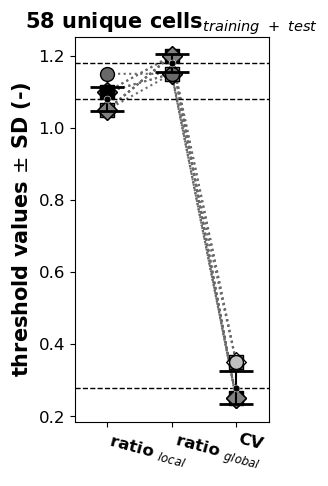

In [30]:

PF.plot_thresholds(thresholds, N_total)

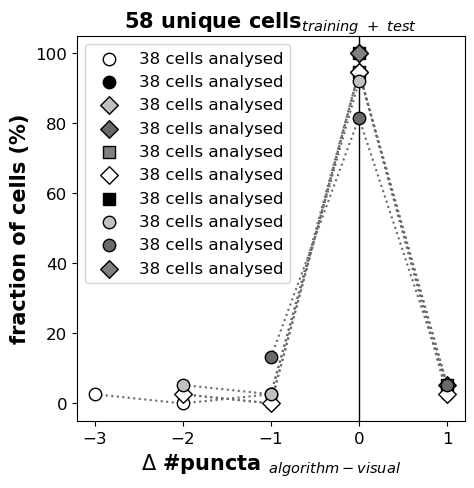

In [31]:
# extract data pertaining to training set
dif_training = differences[0]
N_train = N_training_test[0]

# make the plot
PF.plot_detected_vs_visual(dif_training, N_total, N_train)

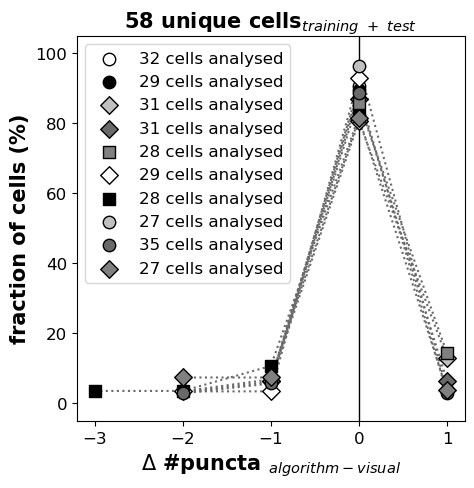

In [32]:
# extract data pertaining to training set
dif_test = differences[1]
N_test = N_training_test[1]

# make the plot
PF.plot_detected_vs_visual(dif_test, N_total, N_test)

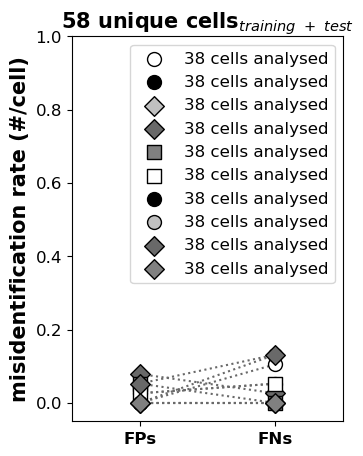

In [33]:
# extract data pertaining to training set
errors_training = errors[0]
N_train = N_training_test[0]

# make the plot
PF.plot_error_rates(errors_training, N_total, N_train)

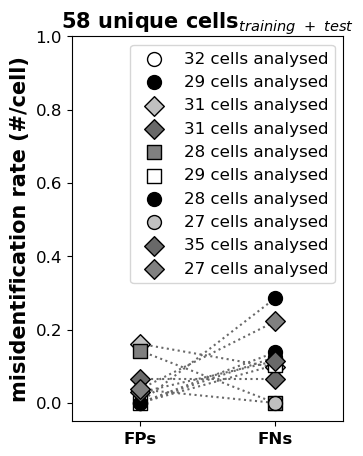

: 

In [ ]:
# extract data pertaining to test set
errors_test = errors[1]
N_test = N_training_test[1]

# make the plot
PF.plot_error_rates(errors_test, N_total, N_test)

In [471]:
# print(av_thresholds)
T_local = av_thresholds[0]
T_global = av_thresholds[1]
T_CV = av_thresholds[2]
print(f"Average thresholds from bootstrapping: T_local = {T_local}, T_global = {T_global}, T_CV = {T_CV}")


Average thresholds from bootstrapping: T_local = 1.0550000000000002, T_global = 1.1, T_CV = 0.27


## Run PunctaFinder and count PV+ somata

In [469]:

def analyze_puncta_image(output_file_path, egfp_file_path, csv_save_path):
    print("Loading image stacks...")
    # 1. Load the filled blob shapes from the previous step
    filled_stack = tiff.imread(output_file_path)
    # 2. Load the matching EGFP channel stack
    egfp_stack = tiff.imread(egfp_file_path)
    
    # Safety checks for dimensions
    if filled_stack.ndim == 2:
        filled_stack = np.expand_dims(filled_stack, axis=0)
        egfp_stack = np.expand_dims(egfp_stack, axis=0)
        
    assert filled_stack.shape == egfp_stack.shape, "Image dimensions do not match!"
    
    num_slices = filled_stack.shape[0]
    puncta_counts_list = []
    
    # 5. Loop through all slices (Z-levels)
    for z in range(num_slices):
        slice_cells = filled_stack[z]
        slice_egfp = egfp_stack[z]
        
        # Identify unique cells in this specific slice (ignoring background 0)
        unique_cells = np.unique(slice_cells)
        unique_cells = unique_cells[unique_cells != 0]
        
        print(f"Processing slice {z+1}/{num_slices}... Found {len(unique_cells)} cells.")
        
        # Loop through each individual cell in the current slice
        for cell_id in unique_cells:
            # Step 1: Generate the binary mask for this specific cell
            cell_mask = (slice_cells == cell_id)
            
            # Step 2: Apply the cell mask to the EGFP channel
            # Pixels outside the cell are set to 0
            EGFP_mask = np.zeros_like(slice_egfp)
            EGFP_mask[cell_mask] = slice_egfp[cell_mask]

            # if > 30% of the cell area (by pixels) has intensity > 700 in EGFP_mask, skip the cell
            if np.sum(EGFP_mask > 700) > 0.3 * np.sum(cell_mask):
                print(f"Slice {z+1}, Cell ID {cell_id} area: {np.sum(cell_mask)} pixels, EGFP positive pixels: {np.sum(EGFP_mask > 700)}.")
                print(f"Slice {z+1}, Cell ID {cell_id}: Skipped due to >30% of pixels with intensity > 700.")
                continue

            else:
                # Step 3: Run your predefined PunctaFinder function
                # Expecting a 1-row DataFrame where column index 1 (the 2nd column) holds the count
                result_df = PF.PunctaFinder(EGFP_mask, cell_mask, 5, 0, T_local, T_global, T_CV)
                
                # Step 4: Extract the puncta value from the 2nd column (index 1) of the first row
                puncta_value = len(result_df.iloc[0, 1])
                print(f"Slice {z+1}, Cell ID {cell_id}: Detected Puncta = {puncta_value}")
                
                # Record it to our master collector
                puncta_counts_list.append(puncta_value)
            
    # Step 4 & 6: Create a single-column DataFrame and save to CSV
    final_df = pd.DataFrame(puncta_counts_list) #, columns=["Detected_Puncta"]
    
    final_df.to_csv(csv_save_path, index=False)
    print(f"\nAnalysis complete! Total cells analyzed: {len(final_df)}")
    print(f"Results saved to: {csv_save_path}")


In [470]:

# input_path = "D:\\anatomy_data\\DK95\\MaskID-DK95_slide2_section5_40x_FB.tif"
# output_path = "D:\\anatomy_data\\DK95\\FilledMask-DK95_slide2_section5_40x_FB.tif"

# fill_blob_outlines(input_path, output_path)

current_image_path = "D:\\anatomy_data\\DK95\\MaskID-DK95_slide2_section5_40x_FB.tif"
EGFP_path = "D:\\anatomy_data\\DK95\\C2-DK95_slide2_section5_40x_EGFP_smooth.tif"
current_tracer = "FB"
file_ID = "DK95_slide2_section5_40x"
current_directory = "D:\\anatomy_data\\DK95"


# Example execution
if __name__ == "__main__":
    # Define your file paths here
    PN_image_path = current_image_path  # Output from previous scripts
    egfp_tiff = EGFP_path       # Your raw experimental EGFP channel
    output_csv = current_directory + f"\\{file_ID}_{current_tracer}_puncta_counts.csv"
    
    analyze_puncta_image(PN_image_path, egfp_tiff, output_csv)

Loading image stacks...
Processing slice 1/9... Found 1 cells.
Slice 1, Cell ID 1: Detected Puncta = 5
Processing slice 2/9... Found 2 cells.
Slice 2, Cell ID 2: Detected Puncta = 7
Slice 2, Cell ID 3 area: 2838 pixels, EGFP positive pixels: 1210.
Slice 2, Cell ID 3: Skipped due to >30% of pixels with intensity > 700.
Processing slice 3/9... Found 2 cells.
Slice 3, Cell ID 4 area: 1635 pixels, EGFP positive pixels: 781.
Slice 3, Cell ID 4: Skipped due to >30% of pixels with intensity > 700.
Slice 3, Cell ID 5: Detected Puncta = 11
Processing slice 4/9... Found 1 cells.
Slice 4, Cell ID 6 area: 1365 pixels, EGFP positive pixels: 494.
Slice 4, Cell ID 6: Skipped due to >30% of pixels with intensity > 700.
Processing slice 5/9... Found 0 cells.
Processing slice 6/9... Found 2 cells.
Slice 6, Cell ID 7: Detected Puncta = 1
Slice 6, Cell ID 8: Detected Puncta = 4
Processing slice 7/9... Found 3 cells.
Slice 7, Cell ID 9: Detected Puncta = 5
Slice 7, Cell ID 10: Detected Puncta = 8
Slice 7, 

In [368]:
## PV+ cell body (tdTomato) counting: segmentation with overlap exclusion across Z-slices

import numpy as np
import pandas as pd
import tifffile as tiff
from scipy.ndimage import binary_fill_holes
from skimage.filters import threshold_otsu
from skimage.morphology import disk, opening, remove_small_objects
from skimage.measure import label

def count_neurons_with_overlap_exclusion(input_path, output_csv_path, axon_max_width=5, min_soma_area=50):
    print(f"Loading fluorescence stack: {input_path}")
    stack = tiff.imread(input_path)
    
    if stack.ndim == 2:
        stack = np.expand_dims(stack, axis=0)
        
    num_slices = stack.shape[0]
    
    radius = int(np.ceil(axon_max_width / 2)) + 1
    selem = disk(radius)
    
    total_unique_cells = 0
    previous_slice_mask = None
    slice_counts = []

    print("\nProcessing slices and calculating overlap exclusions...")
    for z in range(num_slices):
        slice_data = stack[z]
        
        # Default tracking if the slice is completely empty
        if np.max(slice_data) == 0:
            slice_counts.append({"Slice": z + 1, "New_Cells_Discovered": 0})
            previous_slice_mask = np.zeros_like(slice_data, dtype=bool)
            continue
            
        # Step 1-4: Clean up image to isolate cell bodies (somas)
        thresh = threshold_otsu(slice_data)
        binary_mask = slice_data > thresh
        axon_free_mask = opening(binary_mask, selem)
        filled_somas = binary_fill_holes(axon_free_mask)
        clean_somas_current = remove_small_objects(filled_somas, min_size=min_soma_area)
        
        # Label each individual cell body on the CURRENT slice
        labeled_current, num_features = label(clean_somas_current, return_num=True)
        
        new_cells_in_slice = 0
        
        # Step 5: Check every detected cell for overlap with the previous slice
        for cell_idx in range(1, num_features + 1):
            cell_mask = (labeled_current == cell_idx)
            cell_area = np.sum(cell_mask)
            
            # If it's the very first slice, there is no previous data to overlap with
            if z == 0 or previous_slice_mask is None:
                new_cells_in_slice += 1
            else:
                # Calculate how many pixels of this cell overlap with any cell from the last slice
                overlap_pixels = np.sum(cell_mask & previous_slice_mask)
                overlap_ratio = overlap_pixels / cell_area
                
                # Exclude if overlap is less than 50%
                if overlap_ratio < 0.50:
                    new_cells_in_slice += 1
                    
        total_unique_cells += new_cells_in_slice
        slice_counts.append({
            "Slice": z + 1, 
            "New_Cells_Discovered": new_cells_in_slice
        })
        
        print(f" -> Slice {z+1}/{num_slices}: Counted {new_cells_in_slice} new cells (Excluded {num_features - new_cells_in_slice} continuations)")
        
        # Save current mask to compare against the next slice
        previous_slice_mask = clean_somas_current

    print(f"\n>> Grand Total Unique Neuronal Cell Bodies: {total_unique_cells} <<")

    image_PV_count = total_unique_cells

    return image_PV_count
    
    # # Save a simple per-slice breakdown to CSV
    # df = pd.DataFrame(slice_counts)
    # # Append the final total summary row at the bottom of the CSV
    # df = pd.concat([df, pd.DataFrame([{"Slice": "TOTAL UNIQUE NEURONS", "New_Cells_Discovered": total_unique_cells}])], ignore_index=True)
    
    # df.to_csv(output_csv_path, index=False)
    # print(f"Summary saved to: {output_csv_path}") # summary csv not needed; edit so final count can be written directly into sypCountSheet


In [369]:
# # set output directory to the same directory as the input TIFF
# output_dir = Path(input_tiff).parent

current_directory = "D:\\anatomy_data\\DK95"
file_ID = "DK95_slide2_section5_40x"

if __name__ == "__main__":
    # Define your parameters here
    input_tiff = current_directory + f"\\C1-DK95_slide2_section5_40x_tdTom.tif"
    output_csv = current_directory + f"\\{file_ID}_PV_count.csv"
    
    # Run the filter pipeline
    count_neurons_with_overlap_exclusion(
        input_path=input_tiff, 
        output_csv_path= output_csv,
        axon_max_width=20,    # Tweak based on your image magnification/pixel resolution
        min_soma_area=150     # Tweak to filter out tiny dust artifacts
    )

Loading fluorescence stack: D:\anatomy_data\DK95\C1-DK95_slide2_section5_40x_tdTom.tif

Processing slices and calculating overlap exclusions...
 -> Slice 1/9: Counted 3 new cells (Excluded 0 continuations)
 -> Slice 2/9: Counted 1 new cells (Excluded 1 continuations)
 -> Slice 3/9: Counted 3 new cells (Excluded 1 continuations)
 -> Slice 4/9: Counted 1 new cells (Excluded 2 continuations)
 -> Slice 5/9: Counted 2 new cells (Excluded 1 continuations)
 -> Slice 6/9: Counted 0 new cells (Excluded 2 continuations)
 -> Slice 7/9: Counted 3 new cells (Excluded 2 continuations)
 -> Slice 8/9: Counted 0 new cells (Excluded 0 continuations)
 -> Slice 9/9: Counted 0 new cells (Excluded 0 continuations)

>> Grand Total Unique Neuronal Cell Bodies: 13 <<


## Write results into excel file

In [380]:
import os
import glob
import re
import pandas as pd

def compile_analysis_data(directory_path, csv_file_path, PV_count):
    """
    Consolidates cell puncta data arrays and global neuron counts into a master Excel file
    using only Pandas.
    """
   # 1. Load the existing CSV file if it exists, otherwise start with a blank DataFrame
    if os.path.exists(csv_file_path):
        master_df = pd.read_csv(csv_file_path)
    else:
        master_df = pd.DataFrame(columns=["Image Name", "Slide #", "Section #", "# of Synapses", "Cell Type", "# of Neurons"])

    csv_pattern = os.path.join(directory_path, "*_puncta_counts.csv")
    csv_files = glob.glob(csv_pattern)
    csv_files.sort(reverse=True) 

    new_rows = []

    for csv_file in csv_files:
        filename = os.path.basename(csv_file)
        
        match = re.search(r"^(.*)_(FB|CTB)_puncta_counts\.csv$", filename)
        if not match:
            continue  
            
        base_image_name = match.group(1)      
        tracer_type = match.group(2)          
        cell_type_string = f"{tracer_type}_subtype"
        
        data_df = pd.read_csv(csv_file, header=None)
        puncta_counts = data_df[0].tolist()
        
        for val in puncta_counts:
            new_rows.append({
                "Image Name": base_image_name,
                "Slide #": None,       
                "Section #": None,
                "# of Synapses": int(val),
                "Cell Type": cell_type_string,
                "Basket Cells": None   
            })

    if new_rows:
        new_data_df = pd.DataFrame(new_rows)
        new_data_df.at[0, "Basket Cells"] = int(PV_count)
        master_df = pd.concat([master_df, new_data_df], ignore_index=True)

    # Save out as a flat CSV file (completely bypasses openpyxl)
    master_df.to_csv(csv_file_path, index=False)

In [381]:

# Pipeline Execution Example
if __name__ == "__main__":
    # Example simulated output value from count_neurons_with_overlap_exclusion calculation function
    detected_PV = 13 # image_PV_count
    
    # Run structural pipeline compilation logic block
    compile_analysis_data(
        directory_path="C:\\Users\\bl231\\OneDrive\\DOCUME~1-Serendipity-217938\\Github\\PunctaFinder", 
        csv_file_path="M1_anatomy_sypCountSheet_DK95.csv", 
        PV_count=detected_PV
    )

**Code cell stash**
TBD whether to keep or not

In [ ]:

# do this for all slices in the z stack
for z in range(mask.shape[0]): # iterate over slices (z-axis)

    cells_in_slice = len(np.unique(mask[z])) - 1 # subtract 1 for background
    print(f"no. of cells: {cells_in_slice}") # print number of cells in the slice (subtract 1 for background)

    for row in range(mask.shape[1]): # iterate over rows (y-axis)
        non_zero_indices = np.where(mask[z, row, :] != 0)[0] # get indices of non-zero pixels in the row
        pixel_values = mask[z, row, non_zero_indices] 
        cells_in_row = np.unique(pixel_values) # get unique cell values in the row

        if len(non_zero_indices) > 1: # if there are at least two non-zero pixels
            # determine if there are 2 or more groups of continuous non-zero pixels in the row
            groups = np.split(non_zero_indices, np.where(np.diff(non_zero_indices) != 1)[0] + 1) # split the indices into groups of continuous pixels
            
            if len(groups) == 1: # if there is only 1 group of continuous pixels
                start_idx = non_zero_indices[0]
                end_idx = non_zero_indices[-1]
                mask[z, row, start_idx:end_idx + 1] = cells_in_row[0] # set all pixels between the first and last non-zero pixel to the value of the first non-zero pixel

            
            elif len(groups) > 1: # if there are 2 or more groups of continuous non-zero pixels
                for i in range(len(cells_in_row)): # iterate over the unique cell values in the row
                    cell_num = cells_in_row[i] # get the current cell number
                    group_indices = np.where(pixel_values == cell_num) # get the indices of the current cell number in the pixel_values array
                    print(group_indices)

                    # if len(group_indices) > 0: # if there are any pixels with the current cell value
                    #     group_start_idx = non_zero_indices[group_indices[0]] # get the first index of the current group
                    #     group_end_idx = non_zero_indices[group_indices[-1]] # get the last index of the current group
                    #     mask[z, row, group_start_idx:group_end_idx + 1] = cell_num # set all pixels between the first and last pixel of the current group to the current cell value

                    for j in range(len(groups) - 1): # iterate over the groups of continuous non-zero pixels
                        group_start_idx = groups[i][0] # get the first index of the current group
                        group_end_idx = groups[i][-1] # get the last index of the current group
                        mask[z, row, group_start_idx:group_end_idx + 1] = cells_in_row[i] # set all pixels between the first and last pixel of the current group to the number of the first non-zero pixel
            


    

    # if cell_count == 1:
    #     # create a binary mask where all non-zero pixels = true, and all zero pixels = false
    #     binary_mask = mask[z] > 0
    #     # find the coordinates of the non-zero pixels
    #     coords = np.column_stack(np.where(binary_mask))
    #     # find the bounding box of the non-zero pixels
    #     min_row, min_col = coords.min(axis=0)
    #     max_row, max_col = coords.max(axis=0)
    #     print(f"bounding box: ({min_row}, {min_col}) to ({max_row}, {max_col}), shape: ({binary_mask.shape})")

# visualise the masked cell
# PF.plot_masked_cell(puncta_img, binary_mask)
                    
# # visualize a slice in mask z stack
# plt.imshow(mask[5])
# plt.show()


To do?
1. obtain or create cell masks first - "The cell masks were obtained with BudJ applied to the bright-field image. As indicated in the image, each cell mask has its own unique value, _i.e._ all pixels with value 1 belong to cell mask 1, etc."
2. find parameters (thresholds etc.) that seem to work best for my data
3. once PF is working, play around with code for validation & visualization (some from Gabe in this notebook)

In [ ]:
from PF_functions import PunctaFinder
from joblib import Parallel, delayed

# segmenting image to detect puncta in full field (not within cell masks)
# edit as needed to fit my data

def PF_parpool(fluor_image, 
                    pf_params = {
                        'punctum_diameter': 3,
                        'overlap': 0,
                        'threshold_ratio_local': 2,
                        'threshold_ratio_overall': 2,
                        'threshold_cv': 1,
                    },
                    n_jobs = -1):
    grid_sz = int(np.sqrt(fluor_image.shape[0]))*2
    bounds = np.arange(0,fluor_image.shape[0],grid_sz)

    def run_pf_parallel(xy):
    # results = []
    # for xy in [(x,y) for x in np.arange(len(bounds)-1) for y in np.arange(len(bounds)-1)]:
        cell_mask = np.zeros((fluor_image.shape[0], fluor_image.shape[1]), dtype=int)
        cell_mask[bounds[xy[1]]:bounds[xy[1]+1],bounds[xy[0]]:bounds[xy[0]+1]] = 1
        cell_mask[0:pf_params['punctum_diameter'],:] = 0
        cell_mask[:,0:pf_params['punctum_diameter']] = 0
        cell_mask[-pf_params['punctum_diameter']:,:] = 0
        cell_mask[:,-pf_params['punctum_diameter']:] = 0
        
        df_stack = PunctaFinder(
            fluor_image,
            cell_mask,
            pf_params['punctum_diameter'],
            pf_params['overlap'],
            pf_params['threshold_ratio_local'],
            pf_params['threshold_ratio_overall'],
            pf_params['threshold_cv']
        )
        
        first_true = np.argwhere(cell_mask==1)
        if df_stack['coordinates [x,y]'][0] is not None:
            temp_coords = []
            for tc in df_stack['coordinates [x,y]'][0]:
                temp_x = tc[0] + first_true[0][1] - pf_params['punctum_diameter']
                temp_y = tc[1] + first_true[0][0] - pf_params['punctum_diameter']
                temp_coords.append([temp_x,temp_y])
            df_stack.loc[0, 'coordinates [x,y]'] = [temp_coords]
        # results.append(df_stack)
        return df_stack
        
    results = Parallel(n_jobs, backend='loky')(
        delayed(run_pf_parallel)(xy) for xy in [(x,y) for x in np.arange(len(bounds)-1) for y in np.arange(len(bounds)-1)]
    )
        
    return pd.concat([r for r in results])

In [ ]:
from PF_functions import PF_stack
from joblib import Parallel, delayed

def PF_stack_parpool(fluor_stack, pDiam = 3, overlap = 0, dZ = 2, trl = 2, tro = 2, tcv = 2, n_jobs = -1):
    pf_params = {
        'punctum_diameter': pDiam,
        'overlap': overlap,
        'delta_z': dZ,
        'threshold_ratio_local': trl,
        'threshold_ratio_overall': tro,
        'threshold_cv': tcv,
    }
    grid_sz = int(np.sqrt(fluor_stack.shape[1]))*2
    bounds = np.arange(0,fluor_stack.shape[1],grid_sz)

    def run_stack_parallel(xy):
    # results = []
    # for xy in [(x,y) for x in np.arange(len(bounds)-1) for y in np.arange(len(bounds)-1)]:
        cell_mask = np.zeros((fluor_stack.shape[1], fluor_stack.shape[2]), dtype=int)
        cell_mask[bounds[xy[1]]:bounds[xy[1]+1],bounds[xy[0]]:bounds[xy[0]+1]] = 1
        cell_mask[0:pf_params['punctum_diameter']+1,:] = 0
        cell_mask[:,0:pf_params['punctum_diameter']+1] = 0
        cell_mask[(pf_params['punctum_diameter']+1)*-1:,:] = 0
        cell_mask[:,(pf_params['punctum_diameter']+1)*-1:] = 0
        
        df_stack, df_rejected = PF_stack(
            fluor_stack,
            cell_mask,
            pf_params['punctum_diameter'],
            pf_params['overlap'],
            pf_params['delta_z'],
            pf_params['threshold_ratio_local'],
            pf_params['threshold_ratio_overall'],
            pf_params['threshold_cv']
        )
        
        first_true = np.argwhere(cell_mask==1)
        df_stack['x'] = df_stack['x'] + first_true[0][1] - pf_params['punctum_diameter']
        df_stack['y'] = df_stack['y'] + first_true[0][0] - pf_params['punctum_diameter']
        df_rejected['x'] = df_rejected['x'] + first_true[0][1] - pf_params['punctum_diameter']
        df_rejected['y'] = df_rejected['y'] + first_true[0][0] - pf_params['punctum_diameter']
        # results.append([df_stack, df_rejected])
        return df_stack, df_rejected
        
    results = Parallel(n_jobs, backend='loky')(
        delayed(run_stack_parallel)(xy) for xy in [(x,y) for x in np.arange(len(bounds)-1) for y in np.arange(len(bounds)-1)]
    )

    df_all_good = pd.concat([r[0] for r in results if not r[0].empty], ignore_index=True)
    df_all_rejected = pd.concat([r[1] for r in results if not r[1].empty], ignore_index=True)
    return df_all_good, df_all_rejected  

In [ ]:
file_dir = "D:\\anatomy_data\\DK77\\DK77_slide2_section8_40x_Composite.tif" # currently set arbitrarily for testing
green_chan = 1
red_chan = 2

dir = Path(file_dir).parent
file_stem = Path(file_dir).stem
oib = OifFile(file_dir)
ref_params = oib.mainfile['Reference Image Parameter']
x_scale = ref_params['HeightConvertValue']
y_scale = ref_params['WidthConvertValue']
image = imread(file_dir)

df_all_good, df_all_rejected = PF_stack_parpool(image[green_chan,:,:,:], pDiam = 3)

# ********** COMMENT THIS TO ONLY RUN GOOD PUNCTA
puncta = df_all_good.copy(deep=True); type_sfx = 'GoodOnly'

# ********** COMMENT THIS TO EVALUATE ALL PUNCTA
# puncta_all = pd.concat([df_all_good, df_all_rejected])
# puncta = puncta_all.copy(deep=True); type_sfx = 'All'

# ********** COMMENT THIS TO SELECT ONLY PUNCTA WHERE Z-NORMALIZED GREEN > RED
# puncta_all = df_all_good.copy(deep=True)
# # puncta_all = pd.concat([df_all_good, df_all_rejected])
# red_inten = []
# green_inten = []
# for p,puncta in puncta_all.iterrows():
#     red_inten.append(image[red_chan,int(puncta['z']),int(puncta['y']),int(puncta['x'])])
#     green_inten.append(image[green_chan,int(puncta['z']),int(puncta['y']),int(puncta['x'])])
# red_inten_z = (np.array(red_inten)-np.mean(red_inten))/np.std(red_inten)
# green_inten_z = (np.array(green_inten)-np.mean(green_inten))/np.std(green_inten)
# puncta_log = green_inten_z>red_inten_z
# puncta = puncta_all.loc[puncta_log,:]; type_sfx = 'GreenZBrighter'

puncta['x'] = puncta['x']*x_scale
puncta['y'] = puncta['y']*y_scale

puncta_fn = f'{dir}\\{file_stem}_{type_sfx}.pkl'
with open(puncta_fn, 'wb') as file:
    pickle.dump(puncta, file)

In [ ]:
# matplotlib.use('TkAgg')
# fig = plt.figure()
# ax = fig.add_subplot(projection='3d')
# # thresh_log = puncta['intensity ratio, overall']>(puncta['intensity ratio, overall'].mean() + (puncta['intensity ratio, overall'].std()))
# # ax.scatter(puncta.loc[thresh_log,'x'], puncta.loc[thresh_log,'y'], puncta.loc[thresh_log,'z'], s=5)
# ax.scatter(puncta['x'], puncta['y'], puncta['z'], s=5)
# ax.set_xlabel('X')
# ax.set_ylabel('Y')
# ax.set_zlabel('Z')
# plt.show()
# # %matplotlib inline

In [ ]:
# image = imread(fn)
# z_step = 34
# df_all = PF_parpool(image[1,z_step,:,:])

# # fig,ax = plt.subplots(1,1,figsize=(20,20))
# # ax.imshow(syn, interpolation=None)
# df_all['coordinates [x,y]']

# thresh_0_int_rat_all = df_all['intensity ratio, overall'].mean() + (df_all['intensity ratio, overall'].std()*2)
# thresh_1_int_rat_all = df_all['intensity ratio, overall'].mean() + (df_all['intensity ratio, overall'].std())
# thresh_2_int_rat_all = df_all['intensity ratio, overall'].mean()
# print(f'Mean + 2SD = {thresh_0_int_rat_all}\nMean + 1SD = {thresh_1_int_rat_all}\nMean = {thresh_2_int_rat_all}')
# fig,ax = plt.subplots(1,1,figsize=(20,20))
# ax.imshow(image[1,z_step,:,:], interpolation=None)
# # ax.add_patch(plt.Rectangle((bounds[x_grid], bounds[y_grid]), width, width, fill=False, color='red'))
# for p,puncta in df_all.iterrows():
#     if puncta['intensity ratio, overall']>thresh_0_int_rat_all:
#         ax.scatter(puncta['x'], puncta['y'], c="k", s=15, marker="x")
#     elif puncta['intensity ratio, overall']>thresh_1_int_rat_all:
#         ax.scatter(puncta['x'], puncta['y'], c="r", s=15, marker="x")
#     # elif puncta['intensity ratio, overall']>thresh_2_int_rat_all:
#     #     ax.scatter(puncta['x'], puncta['y'], c="b", s=15, marker="x")

In [ ]:
# from skimage import io
# im = io.imread("D:\PunctaFinder\demo_data.tif")
# fluor = im[:,:,1]
# masks = im[:,:,2]
# cell_no = 2
# cell_mask = masks==cell_no

# puncta_size = 3
# cell_mask = np.full_like(masks, 1)
# cell_mask[0:puncta_size,:] = 0
# cell_mask[:,0:puncta_size] = 0
# cell_mask[-puncta_size:,:] = 0
# cell_mask[:,-puncta_size:] = 0

# PF.plot_masked_cell(fluor, cell_mask)

In [ ]:
# %matplotlib inline

In [ ]:
# # Define Windowing Parameters
# # width = 64
# width = 32
# bounds = np.arange(0,1025,width)

# # Load File
# image = imread(fn)
# # Identify Relevant Frame
# z_step = 34
# syn = image[1,z_step,:,:]
# # Identify grid location in frame
# x_grid = 3
# y_grid = 0

# # Comment in following line if thresholding...
# # syn[syn<(syn.mean() + (syn.std()*2))] = 0
# df_all = pd.DataFrame()
# for x_grid in np.arange(0,len(bounds)-1,1):
#     for y_grid in np.arange(0,len(bounds)-1,1):
#         print(' '*10 + f'Analyzing grid ({x_grid},{y_grid})', end = '\r')
#         ## Define windowing mask
#         syn_mask = np.full_like(syn, 0)
#         # Define the "cell mask" that PunctaFinder needs as the grid that's being searched
#         syn_mask[bounds[y_grid]:bounds[y_grid+1],bounds[x_grid]:bounds[x_grid+1]] = 1
#         # Ensure that the "cell mask" doesn't run into edge effects by masking the overall window border
#         syn_mask[0:puncta_size,:] = 0
#         syn_mask[:,0:puncta_size] = 0
#         syn_mask[-puncta_size:,:] = 0
#         syn_mask[:,-puncta_size:] = 0

#         # fig,ax = plt.subplots(1,1,figsize=(10,10))
#         # ax.imshow(syn, interpolation=None)
#         # ax.add_patch(plt.Rectangle((bounds[x_grid], bounds[y_grid]), width, width, fill=False, color='red'))
#         # # ax.imshow(syn_mask)


#         # This is used if the PF_validated_data function is being used...
#         N_cat1 = 1
#         N_cat2 = 0
#         N_cat3 = 0
#         puncta_size = 3
#         df, cropped_cell, mask_cat1, mask_cat2, mask_cat3 = PF.PF_validated_data(syn, syn_mask, puncta_size, 0, N_cat1, N_cat2, N_cat3)

#         # df.insert(0, 'grid_x', np.full(df.shape[0],x_grid).tolist())
#         # df.insert(1, 'grid_y', np.full(df.shape[0],y_grid).tolist())
#         first_true = np.argwhere(syn_mask==1)
#         df['x'] = df['x'] + first_true[0][1] - puncta_size
#         df['y'] = df['y'] + first_true[0][0] - puncta_size

#         df_all = pd.concat([df_all, df.loc[0:20,:]])

#         print('Done')

#         # PF.plot_PF_validated_data(df, cropped_cell, mask_cat1, mask_cat2, mask_cat3)
#         # plt.show()


In [ ]:
# # fig,ax = plt.subplots(1,1,figsize=(20,20))
# # ax.imshow(syn, interpolation=None)

# thresh_0_int_rat_all = df_all['intensity ratio, overall'].mean() + (df_all['intensity ratio, overall'].std()*2)
# thresh_1_int_rat_all = df_all['intensity ratio, overall'].mean() + (df_all['intensity ratio, overall'].std())
# thresh_2_int_rat_all = df_all['intensity ratio, overall'].mean()
# print(f'Mean + 2SD = {thresh_0_int_rat_all}\nMean + 1SD = {thresh_1_int_rat_all}\nMean = {thresh_2_int_rat_all}')
# fig,ax = plt.subplots(1,1,figsize=(20,20))
# ax.imshow(syn, interpolation=None)
# # ax.add_patch(plt.Rectangle((bounds[x_grid], bounds[y_grid]), width, width, fill=False, color='red'))
# for p,puncta in df_all.iterrows():
#     if puncta['intensity ratio, overall']>thresh_0_int_rat_all:
#         ax.scatter(puncta['x'], puncta['y'], c="k", s=15, marker="x")
#     elif puncta['intensity ratio, overall']>thresh_1_int_rat_all:
#         ax.scatter(puncta['x'], puncta['y'], c="r", s=15, marker="x")
#     # elif puncta['intensity ratio, overall']>thresh_2_int_rat_all:
#     #     ax.scatter(puncta['x'], puncta['y'], c="b", s=15, marker="x")